In [1]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

In [2]:

df=pd.read_csv("dirty_cafe_sales.csv")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


In [4]:
df.columns

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date'],
      dtype='str')

In [5]:
df.rename(columns ={"Price Per Unit": "Price_Per_Unit",
                    "Total Spent": "Total_Spent",
                    "Payment Method": "Payment_Method",
                    "Transaction Date": "Transaction_Date"
}, inplace =True)

In [6]:
df.describe()

,Transaction ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


In [7]:
df.head(5)

,Transaction ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [8]:
df.dtypes

Transaction ID      str
Item                str
Quantity            str
Price_Per_Unit      str
Total_Spent         str
Payment_Method      str
Location            str
Transaction_Date    str
dtype: object

In [9]:
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price_Per_Unit"] = pd.to_numeric(df["Price_Per_Unit"], errors="coerce")
df["Total_Spent"] = pd.to_numeric(df["Total_Spent"], errors="coerce")

In [10]:
df["Transaction_Date"] = pd.to_datetime(
    df["Transaction_Date"],
    errors="coerce"
)

In [11]:
corr = df.corr(numeric_only=True)

print(corr)

                Quantity  Price_Per_Unit  Total_Spent
Quantity        1.000000        0.006078     0.704310
Price_Per_Unit  0.006078        1.000000     0.647489
Total_Spent     0.704310        0.647489     1.000000


In [12]:
df.isnull().sum()

Transaction ID         0
Item                 333
Quantity             479
Price_Per_Unit       533
Total_Spent          502
Payment_Method      2579
Location            3265
Transaction_Date     460
dtype: int64

In [13]:
df["Payment_Method"].unique()

<StringArray>
['Credit Card', 'Cash', 'UNKNOWN', 'Digital Wallet', 'ERROR', nan]
Length: 6, dtype: str

In [14]:
df.replace(['ERROR','UNKNOWN'],np.nan,inplace=True)

,Transaction ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2.0,2.0,4.0,NaN,NaN,2023-08-30
9996,TXN_9659401,NaN,3.0,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3.0,NaN,3.0,Digital Wallet,NaN,2023-12-02


In [15]:
df.drop(columns =["Location", "Transaction ID"], inplace =True)

In [16]:
df.drop_duplicates()

,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Transaction_Date
0,Coffee,2.0,2.0,4.0,Credit Card,2023-09-08
1,Cake,4.0,3.0,12.0,Cash,2023-05-16
2,Cookie,4.0,1.0,NaN,Credit Card,2023-07-19
3,Salad,2.0,5.0,10.0,NaN,2023-04-27
4,Coffee,2.0,2.0,4.0,Digital Wallet,2023-06-11
...,...,...,...,...,...,...
9993,Smoothie,2.0,4.0,NaN,Cash,2023-10-20
9994,NaN,4.0,4.0,16.0,NaN,2023-01-08
9996,NaN,3.0,NaN,3.0,Digital Wallet,2023-06-02
9997,Coffee,4.0,2.0,8.0,Digital Wallet,2023-03-02


In [17]:
imputer=SimpleImputer(strategy="median")


In [18]:
columns = ["Quantity", "Price_Per_Unit", "Total_Spent"]
df[columns] = imputer.fit_transform(df[columns])

In [19]:
imputer=SimpleImputer(strategy="most_frequent")
df[['Item']]=imputer.fit_transform(df[['Item']])



In [20]:
imputer = SimpleImputer(
    strategy="constant",
    fill_value="Unknown"
)

df[["Payment_Method"]] = imputer.fit_transform(
    df[["Payment_Method"]]
)

In [22]:
df["Transaction_Date"] = df["Transaction_Date"].fillna(
    df["Transaction_Date"].mode()[0]
)

In [23]:
df

,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Transaction_Date
0,Coffee,2.0,2.0,4.0,Credit Card,2023-09-08
1,Cake,4.0,3.0,12.0,Cash,2023-05-16
2,Cookie,4.0,1.0,8.0,Credit Card,2023-07-19
3,Salad,2.0,5.0,10.0,Unknown,2023-04-27
4,Coffee,2.0,2.0,4.0,Digital Wallet,2023-06-11
...,...,...,...,...,...,...
9995,Coffee,2.0,2.0,4.0,Unknown,2023-08-30
9996,Juice,3.0,3.0,3.0,Digital Wallet,2023-06-02
9997,Coffee,4.0,2.0,8.0,Digital Wallet,2023-03-02
9998,Cookie,3.0,3.0,3.0,Digital Wallet,2023-12-02


In [28]:
df.drop(columns =["Transaction_Date"], inplace =True)

In [21]:
cleaned_data=df


In [22]:
df['Item'].unique

<bound method Series.unique of 0         Coffee
1           Cake
2         Cookie
3          Salad
4         Coffee
          ...   
9995      Coffee
9996       Juice
9997      Coffee
9998      Cookie
9999    Sandwich
Name: Item, Length: 10000, dtype: str>

In [23]:
df.columns

Index(['Item', 'Quantity', 'Price_Per_Unit', 'Total_Spent', 'Payment_Method',
       'Transaction_Date'],
      dtype='str')

In [24]:
cleaned_data.to_csv("cleaned_data_cafe.csv", index=False)

In [104]:


columns = ["Item", "Payment_Method"]

for column in columns:
    label = LabelEncoder()
    df[column] = label.fit_transform(df[column])

In [105]:
labeled_data=df

In [25]:
cleaned_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Item              10000 non-null  str           
 1   Quantity          10000 non-null  float64       
 2   Price_Per_Unit    10000 non-null  float64       
 3   Total_Spent       10000 non-null  float64       
 4   Payment_Method    10000 non-null  str           
 5   Transaction_Date  10000 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(3), str(2)
memory usage: 468.9 KB


In [99]:
import matplotlib.pyplot as plt
import seaborn as sns

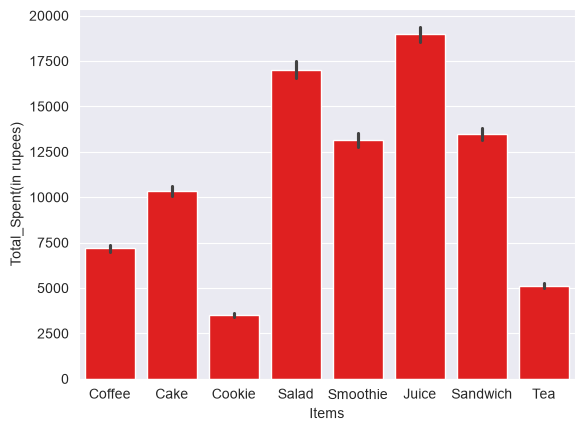

In [100]:
#Which item generates the highest total sales?

sns.barplot(
    data=cleaned_data,
    x="Item",
    y="Total_Spent",
    estimator="sum",
    color="red"
)

plt.xlabel("Items")
plt.ylabel("Total_Spent(in rupees)")


plt.show()

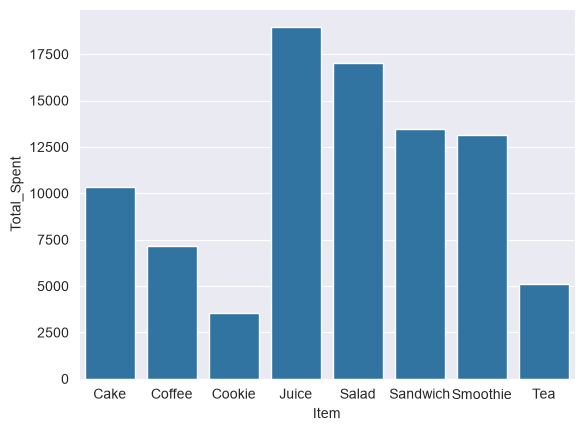

In [40]:
#approach2 with pandas aggregation
sales = df.groupby("Item", as_index=False)["Total_Spent"].sum()

sns.barplot(
    data=sales,
    x="Item",
    y="Total_Spent"
)
plt.show()

In [41]:
print(sales)

       Item  Total_Spent
0      Cake      10341.0
1    Coffee       7184.0
2    Cookie       3526.0
3     Juice      18972.0
4     Salad      17021.0
5  Sandwich      13484.0
6  Smoothie      13132.0
7       Tea       5119.5


In [43]:
quantity_by_item = (
    df.groupby("Item", as_index=False)["Quantity"]
      .sum()
      .sort_values("Quantity", ascending=False)
)

print(quantity_by_item)

       Item  Quantity
3     Juice    6435.0
1    Coffee    3551.0
4     Salad    3469.0
0      Cake    3467.0
5  Sandwich    3428.0
6  Smoothie    3353.0
7       Tea    3319.0
2    Cookie    3249.0


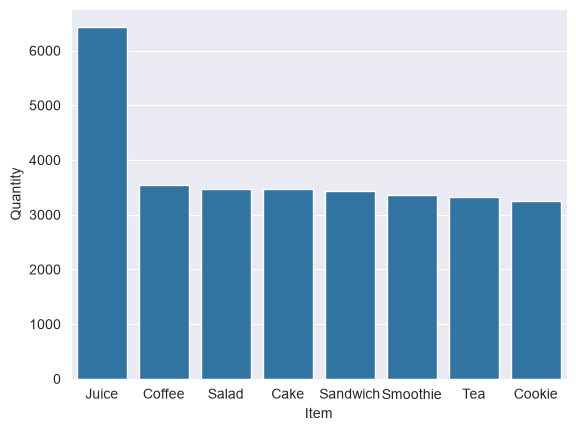

In [44]:


sns.barplot(
    data=quantity_by_item,
    x="Item",
    y="Quantity"
)
plt.show()


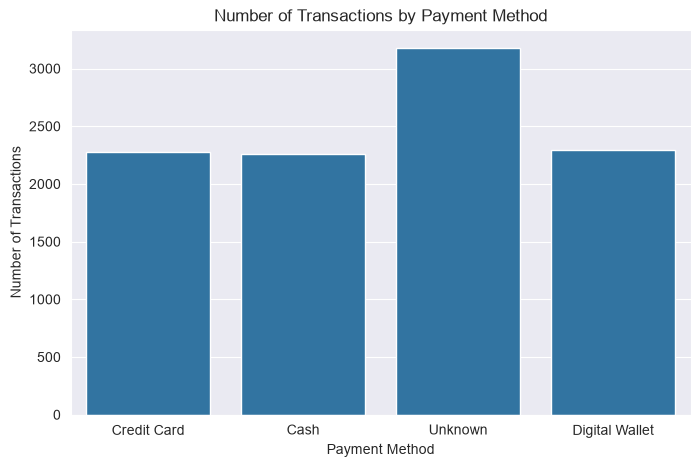

In [45]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Payment_Method"
)

plt.title("Number of Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")

plt.show()

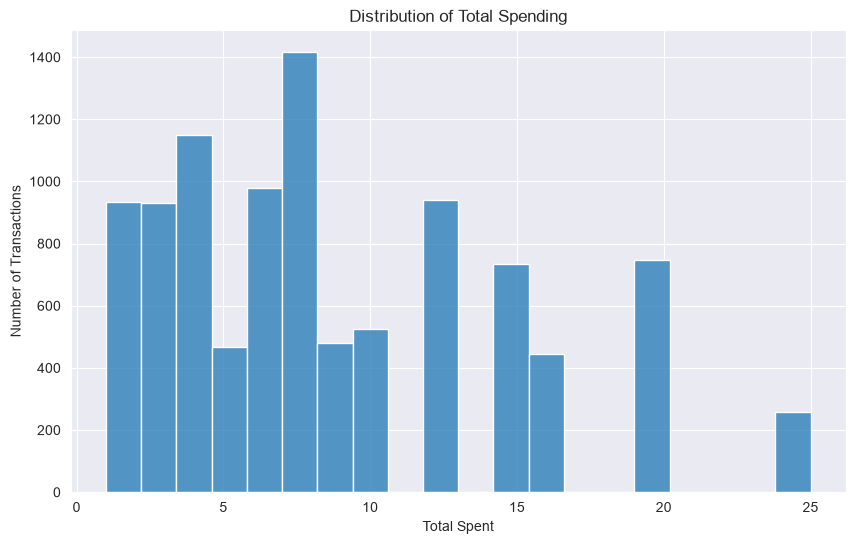

In [46]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Total_Spent",
    bins=20
)

plt.title("Distribution of Total Spending")
plt.xlabel("Total Spent")
plt.ylabel("Number of Transactions")

plt.show()

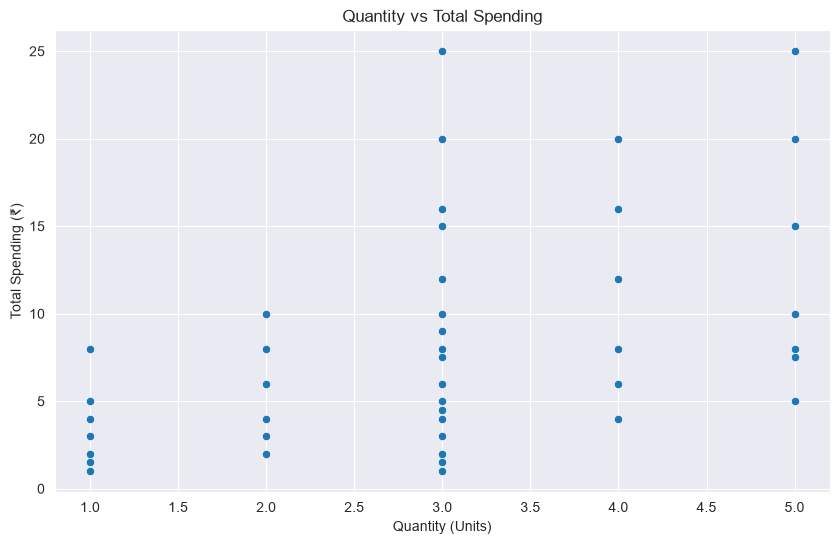

In [47]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total_Spent"
)

plt.title("Quantity vs Total Spending")
plt.xlabel("Quantity (Units)")
plt.ylabel("Total Spending (₹)")

plt.show()

In [106]:
payment_counts = df["Payment_Method"].value_counts()
print(payment_counts)


Payment_Method
3    3178
2    2291
1    2273
0    2258
Name: count, dtype: int64


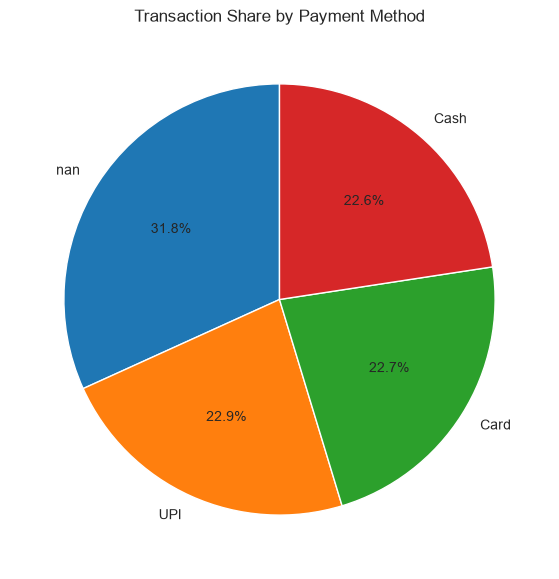

In [107]:
payment_mapping = {
    0: "Cash",
    1: "Card",
    2: "UPI"
}

payment_counts.index = payment_counts.index.map(payment_mapping)



plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Transaction Share by Payment Method")

plt.show()

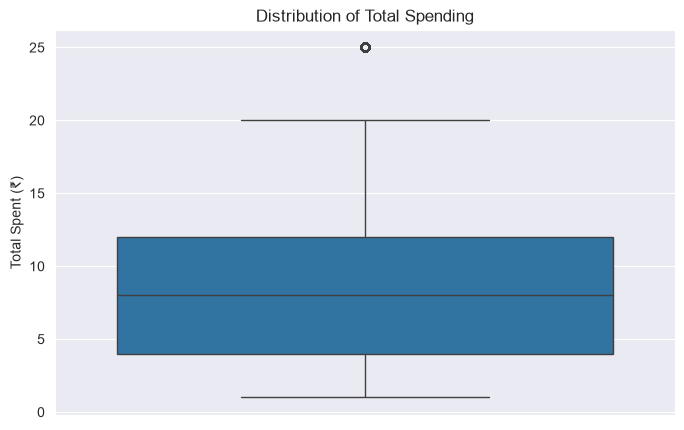

In [114]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, y="Total_Spent")

plt.title("Distribution of Total Spending")
plt.ylabel("Total Spent (₹)")
plt.show()

In [112]:

Q1 = df["Total_Spent"].quantile(0.25)
Q3 = df["Total_Spent"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [115]:
print("Q1 : ", Q1)
print("Q3 : ", Q3)
print("IQR : ", IQR)
print("lower limit : ", lower)
print("upper limit : ", upper)

Q1 :  4.0
Q3 :  12.0
IQR :  8.0
lower limit :  -8.0
upper limit :  24.0


In [113]:
df_clipped = df.copy()

df_clipped["Total_Spent"] = df_clipped["Total_Spent"].clip(
    lower=lower,
    upper=upper
)

In [116]:
 df_clipped["Total_Spent"].max()

np.float64(24.0)

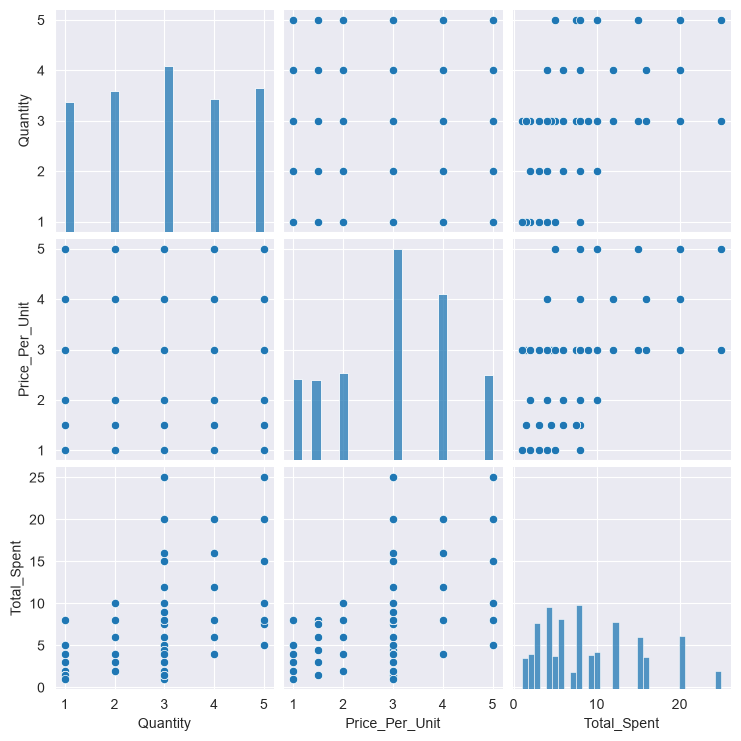

In [51]:
sns.pairplot(
    df[["Quantity", "Price_Per_Unit", "Total_Spent"]],

)

plt.show()

In [52]:
daily_sales = (
    df.groupby("Transaction_Date", as_index=False)["Total_Spent"]
      .sum()
      .sort_values("Transaction_Date")
)

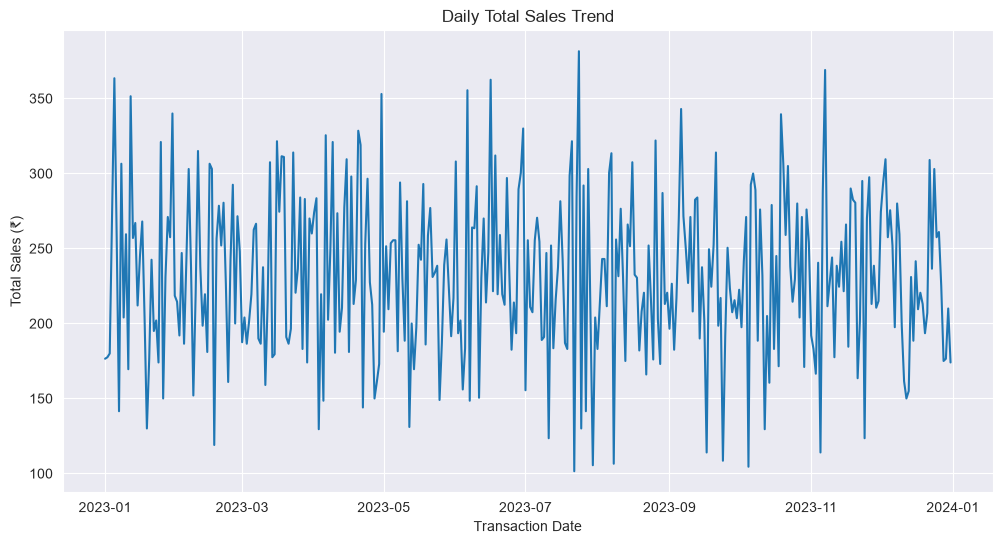

In [101]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=daily_sales,
    x="Transaction_Date",
    y="Total_Spent"
)

plt.title("Daily Total Sales Trend")
plt.xlabel("Transaction Date")
plt.ylabel("Total Sales (₹)")
plt.show()

In [26]:
summary:
highest sale is generated by item "juice"
highest no. of quantities sold : "juice"
highest no. of transations done :"unknown"
highest no.of transactions is done between 5-10 total spent
there is normal relationship between quantity and total spent
there is an outlier in total spending "25"
highest no. of sales done : between 2023-7 to 2023-9


SyntaxError: invalid syntax (999615709.py, line 1)

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[["Quantity", "Price_Per_Unit", "Total_Spent"]] = \
    scaler.fit_transform(
        df[["Quantity", "Price_Per_Unit", "Total_Spent"]]
    )

In [29]:
df.head(5)

,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Transaction_Date
0,Coffee,-0.741832,-0.765858,-0.832373,Credit Card,2023-09-08
1,Cake,0.702686,0.038066,0.532746,Cash,2023-05-16
2,Cookie,0.702686,-1.569783,-0.149813,Credit Card,2023-07-19
3,Salad,-0.741832,1.645914,0.191466,Unknown,2023-04-27
4,Coffee,-0.741832,-0.765858,-0.832373,Digital Wallet,2023-06-11
